In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLOv8

We strive to make our YOLOv8 notebooks work with the latest version of the library. Last tests took place on **06.10.2024** with version **YOLOv8.3.7**.

If you notice that our notebook behaves incorrectly - especially if you experience errors that prevent you from going through the tutorial - don't hesitate! Let us know and open an [issue](https://github.com/roboflow/notebooks/issues) on the Roboflow Notebooks repository.

YOLOv8 can be installed in two ways - from the source and via pip. This is because it is the first iteration of YOLO to have an official package.

In [ ]:
# Pip install method (recommended)

!pip install ultralytics==8.2.103 -q
# prevent ultralytics from tracking your activity
!yolo settings sync=False
from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.103 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 41.9/112.6 GB disk)


In [ ]:
# Git clone method (for development)

# %cd {HOME}
# !git clone github.com/ultralytics/ultralytics
# %cd {HOME}/ultralytics
# !pip install -e .

# from IPython import display
# display.clear_output()

# import ultralytics
# ultralytics.checks()

In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

## CLI Basics

## Inference with Pre-trained COCO Model

### 💻 CLI

`yolo mode=predict` runs YOLOv8 inference on a variety of sources, downloading models automatically from the latest YOLOv8 release, and saving results to `runs/predict`.

In [ ]:
%cd {HOME}
!yolo task=classify mode=predict model=yolov8n-cls.pt conf=0.25 source='https://media.roboflow.com/notebooks/examples/dog.jpeg'

/content
100% 5.31M/5.31M [00:00<00:00, 107MB/s]
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLOv8n-cls summary (fused): 73 layers, 2,715,880 parameters, 0 gradients, 4.3 GFLOPs

100% 104k/104k [00:00<00:00, 58.8MB/s]
100% 755k/755k [00:00<00:00, 126MB/s]
image 1/1 /content/dog.jpeg: 224x224 seat_belt 0.28, Walker_hound 0.24, beagle 0.15, basset 0.11, Labrador_retriever 0.04, 3.4ms
Speed: 49.0ms preprocess, 3.4ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)
Results saved to runs/classify/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [ ]:
model = YOLO(f'{HOME}/yolov8n-cls.pt')
results = model.predict(source='https://media.roboflow.com/notebooks/examples/dog.jpeg', conf=0.25)


Found https://media.roboflow.com/notebooks/examples/dog.jpeg locally at dog.jpeg
image 1/1 /content/dog.jpeg: 224x224 seat_belt 0.28, Walker_hound 0.24, beagle 0.15, basset 0.11, Labrador_retriever 0.04, 2.8ms
Speed: 12.3ms preprocess, 2.8ms inference, 0.1ms postprocess per image at shape (1, 3, 224, 224)


## Custom Training

In [ ]:
# Install / update ultralytics (run once or when needed)
!pip install -U ultralytics

# ────────────────────────────────────────────────
#  Train YOLOv8s-cls (small classification model)
# ────────────────────────────────────────────────

!yolo task=classify mode=train \
    model=yolov8s-cls.pt \
    data="/content/drive/MyDrive/Disease classes" \
    epochs=45 \
    imgsz=128 \
    batch=128 \
    patience=20 \
    device=0

Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=128, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Disease classes, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=45, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=20, p

In [ ]:


# Install ultralytics if not already installed
!pip install -U ultralytics

# Train the YOLOv8 classification model
!yolo task=classify mode=train model=yolov8n-cls.pt \
    data="/content/drive/MyDrive/Disease classes" \
    epochs=25 \
    imgsz=128 \
    batch=32

Ultralytics 8.4.14 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Disease classes, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100,

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil
import os

# Change 'train' to your actual folder name if different
source_folder = "/content/runs/classify/train"
dest_folder   = "/content/drive/MyDrive/Disease_Classification_Results/train_results"

# Create destination if it doesn't exist
os.makedirs(dest_folder, exist_ok=True)

shutil.copytree(source_folder, dest_folder, dirs_exist_ok=True)

print(f"Entire training results saved to: {dest_folder}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entire training results saved to: /content/drive/MyDrive/Disease_Classification_Results/train_results


In [ ]:
# ==============================
# Step 1: Import YOLO
# ==============================
from ultralytics import YOLO
import os

# ==============================
# Step 2: Load your trained model
# ==============================
model = YOLO('/content/runs/classify/train3/weights/best.pt')  # change path if needed

# ==============================
# Step 3: Create "result" folder
# ==============================
os.makedirs("result", exist_ok=True)

# ==============================
# Step 4: Run inference on test data
# ==============================
# If you have a folder with test images
results = model.predict(
    source="/content/drive/MyDrive/Disease classes_split/val/Pneumonia/",  # <-- put your test folder here
    save=True,                     # save predictions
    project="result_16_2_2026",              # save results in "result" folder
    name="model3exp3",                   # subfolder name
    exist_ok=True                  # overwrite if folder exists
)

# ==============================
# Step 5: Check results
# ==============================
print("✅ Inference complete! Results are saved in 'result/model3exp3/'")


image 1/168 /content/drive/MyDrive/Disease classes_split/val/Pneumonia/00001373_010.png: 128x128 Cardiomegaly 0.43, Pneumonia 0.31, Effusion 0.14, No Finding 0.12, Pneumothorax 0.00, 4.9ms
image 2/168 /content/drive/MyDrive/Disease classes_split/val/Pneumonia/00001437_019.png: 128x128 Pneumonia 0.90, No Finding 0.07, Effusion 0.02, Pneumothorax 0.00, Cardiomegaly 0.00, 5.4ms
image 3/168 /content/drive/MyDrive/Disease classes_split/val/Pneumonia/00001582_017.png: 128x128 Pneumonia 0.54, Effusion 0.26, Pneumothorax 0.12, No Finding 0.08, Cardiomegaly 0.00, 4.2ms
image 4/168 /content/drive/MyDrive/Disease classes_split/val/Pneumonia/00001637_001.png: 128x128 Pneumonia 1.00, No Finding 0.00, Pneumothorax 0.00, Effusion 0.00, Cardiomegaly 0.00, 4.3ms
image 5/168 /content/drive/MyDrive/Disease classes_split/val/Pneumonia/00001691_001.png: 128x128 Pneumonia 0.85, Effusion 0.15, Cardiomegaly 0.00, No Finding 0.00, Pneumothorax 0.00, 3.7ms
image 6/168 /content/drive/MyDrive/Disease classes_spl

In [ ]:
# ==============================
# Step 1: Import YOLO
# ==============================
from ultralytics import YOLO
import os

# ==============================
# Step 2: Load your trained model
# ==============================
model = YOLO('/content/runs/classify/train3/weights/best.pt')  # change path if needed

# ==============================
# Step 3: Create "result" folder
# ==============================
os.makedirs("result", exist_ok=True)

# ==============================
# Step 4: Run inference on test data
# ==============================
# If you have a folder with test images
results = model.predict(
    source="/content/drive/MyDrive/Disease classes_split/val/Pneumonia/",  # <-- put your test folder here
    save=True,                     # save predictions
    project="2nd model result_16_2_2026",              # save results in "result" folder
    name="model3exp3",                   # subfolder name
    exist_ok=True                  # overwrite if folder exists
)

# ==============================
# Step 5: Check results
# ==============================
print("✅ Inference complete! Results are saved in 'result/model3exp3/'")

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
from google.colab import drive
import shutil
import os
from datetime import datetime

# Mount Google Drive (only needed if not already mounted)
drive.mount('/content/drive', force_remount=True)

# ────────────────────────────────────────────────
#  SETTINGS - customize these if you want
# ────────────────────────────────────────────────

SOURCE_BASE = "/content/runs/classify"                  # where YOLO saves results
DRIVE_BASE  = "/content/drive/MyDrive/YOLO_Classification_Results"   # main folder in your Drive

# Optional: give your experiment a short name (will be part of the folder)
experiment_name = "disease_cls"          # ← change this for each different dataset/model

# ────────────────────────────────────────────────
#  Create nice timestamp + name folder
# ────────────────────────────────────────────────

today = datetime.now().strftime("%Y-%m-%d")
time_short = datetime.now().strftime("%H%M")

run_folder_name = f"{today}__{experiment_name}__{time_short}"
destination = os.path.join(DRIVE_BASE, run_folder_name)

os.makedirs(destination, exist_ok=True)

print(f"Will save results to:\n{destination}\n")

# ────────────────────────────────────────────────
#  Find the latest train folder (train, train2, train3, ...)
# ────────────────────────────────────────────────

if not os.path.exists(SOURCE_BASE):
    print("Error: No classification results found in /content/runs/classify")
    print("Did training complete successfully?")
else:
    # List folders like train, train2, train3...
    subfolders = [f for f in os.listdir(SOURCE_BASE) if f.startswith("train") and os.path.isdir(os.path.join(SOURCE_BASE, f))]

    if not subfolders:
        print("No 'train*' folders found. Training might not have run.")
    else:
        # Sort by creation time → get the most recent one
        subfolders.sort(key=lambda x: os.path.getctime(os.path.join(SOURCE_BASE, x)), reverse=True)
        latest_run = subfolders[0]
        source_folder = os.path.join(SOURCE_BASE, latest_run)

        print(f"Found latest run: {latest_run}")
        print(f"Copying: {source_folder}  →  {destination}\n")

        # ── Copy everything ───────────────────────────────────────
        try:
            shutil.copytree(source_folder, os.path.join(destination, latest_run), dirs_exist_ok=True)
            print("Copy completed successfully ✓")

            # Optional: also copy best & last weights directly to the parent folder for quick access
            weights_src = os.path.join(source_folder, "weights")
            if os.path.exists(weights_src):
                shutil.copytree(weights_src, os.path.join(destination, "weights"), dirs_exist_ok=True)
                print("Weights folder copied separately for convenience")

        except Exception as e:
            print("Copy failed:", str(e))

print("\nDone!")
print("You can now find everything in your Drive here:")
print(destination.replace("/content/drive/", "MyDrive/"))

Mounted at /content/drive
Will save results to:
/content/drive/MyDrive/YOLO_Classification_Results/2026-04-20__disease_cls__0726

Error: No classification results found in /content/runs/classify
Did training complete successfully?

Done!
You can now find everything in your Drive here:
MyDrive/MyDrive/YOLO_Classification_Results/2026-04-20__disease_cls__0726


In [ ]:
!ls -la {HOME}/runs/classify/train/

ls: cannot access '{HOME}/runs/classify/train/': No such file or directory


In [ ]:
!cat {HOME}/runs/classify/train/results.csv | head -10

                  epoch,             train/loss,  metrics/accuracy_top1,  metrics/accuracy_top5,               val/loss,                 lr/pg0,                 lr/pg1,                 lr/pg2
                      1,                0.85584,                0.95459,                      1,                 1.1213,             0.00023752,             0.00023752,             0.00023752
                      2,                0.31146,                0.96082,                      1,                  1.102,             0.00045669,             0.00045669,             0.00045669
                      3,                 0.2424,                0.96082,                      1,                 1.0905,             0.00065701,             0.00065701,             0.00065701
                      4,                0.21304,                0.96972,                      1,                 1.0869,             0.00062918,             0.00062918,             0.00062918
                      5,                

## Validate Custom Model

In [ ]:
%cd {HOME}

!yolo task=classify mode=val model={HOME}/runs/classify/train/weights/best.pt data={dataset.location}

/content
Ultralytics YOLOv8.2.103 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla T4, 15102MiB)
YOLOv8n-cls summary (fused): 73 layers, 1,442,566 parameters, 0 gradients, 3.3 GFLOPs
train: /content/datasets/banana-ripeness-classification-1/train... found 7862 images in 6 classes ✅ 
val: /content/datasets/banana-ripeness-classification-1/val... found 1123 images in 6 classes ✅ 
test: /content/datasets/banana-ripeness-classification-1/test... found 562 images in 6 classes ✅ 
val: Scanning /content/datasets/banana-ripeness-classification-1/val... 1123 images, 0 corrupt: 100% 1123/1123 [00:00<?, ?it/s]
               classes   top1_acc   top5_acc: 100% 71/71 [00:03<00:00, 22.94it/s]
                   all      0.984          1
Speed: 0.0ms preprocess, 0.6ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to runs/classify/val
💡 Learn more at https://docs.ultralytics.com/modes/val


## Inference with Custom Model

In [ ]:
%cd {HOME}
!yolo task=classify mode=predict model={HOME}/runs/classify/train/weights/best.pt conf=0.25 source={dataset.location}/test/overripe

[Errno 2] No such file or directory: '{HOME}'
/content
/bin/bash: line 1: yolo: command not found


In [ ]:
from google.colab import drive
import shutil
import os
from datetime import datetime

# Mount Drive
drive.mount('/content/drive', force_remount=True)

# Source folder (your prediction results)
source_folder = "/content/runs/classify/result_16_2_2026/model3exp3"

# Destination in Drive – you can change the name or path
today = datetime.now().strftime("%Y-%m-%d")
dest_folder_name = f"Prediction_{today}_predict2"
destination = f"/content/drive/MyDrive/YOLO_Classification_Results/{dest_folder_name}"

# Create folder if it doesn't exist
os.makedirs(destination, exist_ok=True)

# Copy everything
try:
    shutil.copytree(source_folder, os.path.join(destination, "predict2"), dirs_exist_ok=True)
    print("Successfully copied predict2 folder to:")
    print(destination.replace("/content/drive/", "MyDrive/"))
    print("\nInside you'll find:")
    print("• labels/           ← txt files with predictions per image")
    print("• predict2/         ← sometimes nested – check both")
    print("• confusion_matrix.png, results.png, etc.")
    print("• prediction images with boxes/labels drawn")
except Exception as e:
    print("Copy failed:", str(e))
    print("Check if the source folder exists:")
    !ls -la /content/runs/classify

Mounted at /content/drive
Copy failed: [Errno 2] No such file or directory: '/content/runs/classify/result_16_2_2026/model3exp3'
Check if the source folder exists:
ls: cannot access '/content/runs/classify': No such file or directory


## Save and Deploy model

Once you have finished training your YOLOv8 model, you’ll have a set of trained weights ready for use. These weights will be in the `/runs/classify/train/weights/best.pt` folder of your project. You can upload and your model weights to Roboflow Deploy for autolabeling, autoscaling inference, and using later.

The `.deploy()` function in the [Roboflow pip package](https://docs.roboflow.com/python) supports uploading YOLOv8 weights.

Run this cell to save your model weights:

In [ ]:
project.version(dataset.version).deploy(model_type="yolov8-cls", model_path=f"{HOME}/runs/classify/train/")

Dependency ultralytics==8.0.196 is required but found version=8.3.7, to fix: `pip install ultralytics==8.0.196`
Would you like to continue with the wrong version of ultralytics? y/n: y
View the status of your deployment at: https://app.roboflow.com/model-examples/banana-ripeness-classification-cdvrn/1
Share your model with the world at: https://universe.roboflow.com/model-examples/banana-ripeness-classification-cdvrn/model/1


Follow the links above to check if the upload succeeded. It may take a couple of minutes until the model is visible to the `roboflow` SDK.

In [ ]:
# Run inference on your model on a persistant, auto-scaling, cloud API

# Load model
model = project.version(dataset.version).model
assert model, "Model deployment is still loading"

# Choose a random test image
import os, random, glob
test_set_loc = dataset.location + "/test/images/"
random_test_image = random.choice(glob.glob(f"{dataset.location}/test/**/*.jpg"))
print("running inference on " + random_test_image)

pred = model.predict(random_test_image).json()
pred

NameError: name 'project' is not defined

In [ ]:
from google.colab import drive
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow
import os
from datetime import datetime

# Mount Google Drive
drive.mount('/content/drive')

# ====================== CHANGE THIS PATH ======================
# Put the correct path to your best.pt file here
MODEL_PATH = "/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/train3/weights/best.pt"

# Load the trained model
model = YOLO(MODEL_PATH)

print("✅ Model loaded successfully!")
print(f"Model path: {MODEL_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Model loaded successfully!
Model path: /content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/train3/weights/best.pt


In [ ]:
model = YOLO("/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/train3/weights/best.pt")   # your actual best.pt path

In [ ]:
# Install Ultralytics
!pip install -U ultralytics

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("✅ Ultralytics installed and Drive mounted!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 83.9 MB/s eta 0:00:00
Mounted at /content/drive
✅ Ultralytics installed and Drive mounted!


📁 Output folder: /content/drive/MyDrive/YOLO_Classification_Results/Output_Results

📤 Please upload your Chest X-ray image...


Saving 00001364_003.png to 00001364_003.png
✅ Uploaded file: 00001364_003.png

image 1/1 /content/00001364_003.png: 128x128 No Finding 1.00, Pneumothorax 0.00, Pneumonia 0.00, Effusion 0.00, Cardiomegaly 0.00, 3.6ms
Speed: 7.2ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 128, 128)

✅ Prediction: No Finding
📊 Confidence: 99.8%
📁 Result saved to: /content/drive/MyDrive/YOLO_Classification_Results/Output_Results/predicted_No Finding_20260414_160159.jpg


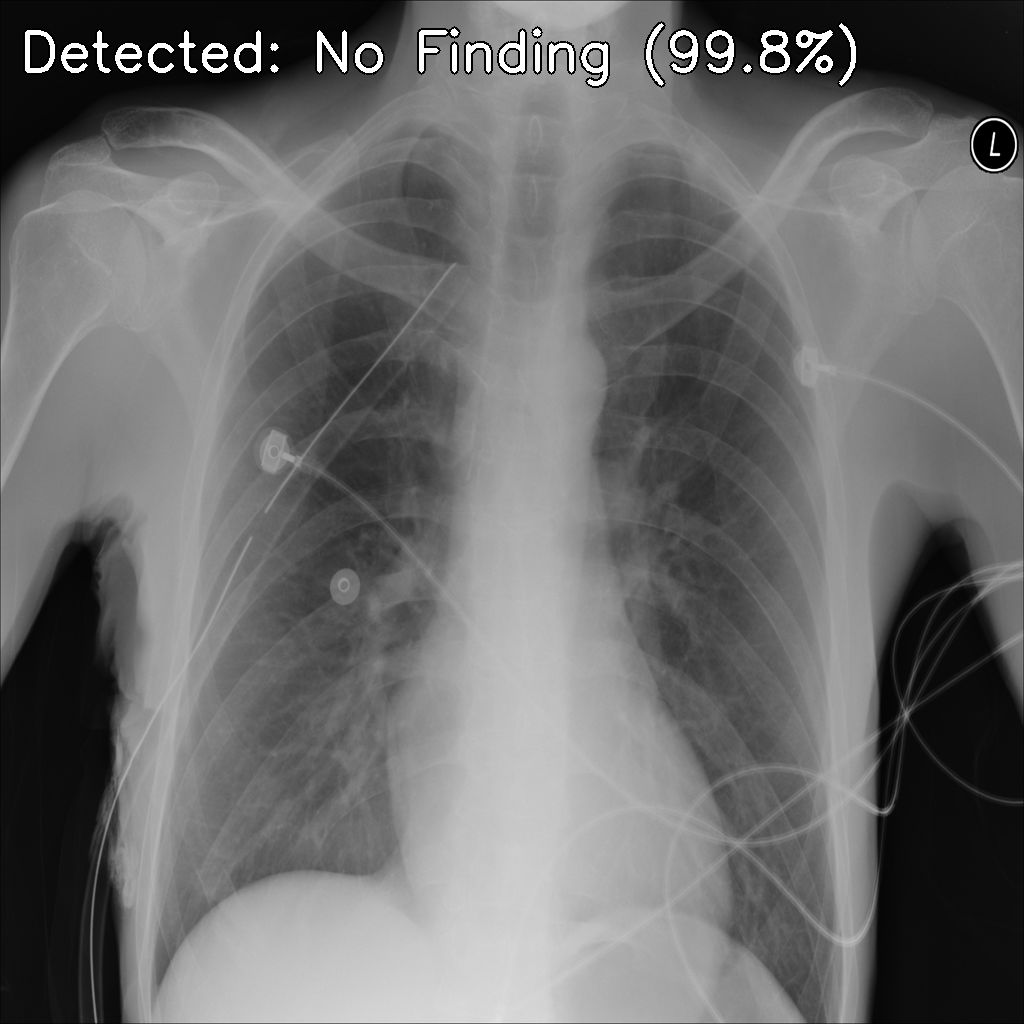

In [ ]:
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow
import os
from datetime import datetime
from google.colab import files

# ====================== SETTINGS ======================
base_folder = "/content/drive/MyDrive/YOLO_Classification_Results"
output_folder = os.path.join(base_folder, "Output_Results")
os.makedirs(output_folder, exist_ok=True)

print(f"📁 Output folder: {output_folder}")

print("\n📤 Please upload your Chest X-ray image...")

uploaded = files.upload()

if uploaded:
    filename = list(uploaded.keys())[0]
    input_image_path = f"/content/{filename}"
    print(f"✅ Uploaded file: {filename}")
else:
    print("❌ No file uploaded!")
    raise SystemExit("Please upload an image.")

# ====================== Run Prediction ======================
results = model.predict(source=input_image_path, save=False, conf=0.5)

pred_class = results[0].names[results[0].probs.data.argmax().item()]
confidence = results[0].probs.data.max().item() * 100

# Load image
img = cv2.imread(input_image_path)
h, w = img.shape[:2]

# ================== IMPROVED TEXT SETTINGS ==================
# Dynamically adjust font size and position based on image size
if h < 300:                    # For small images like 128x128
    font_scale = 0.8
    thickness = 2
    y_position = 30
elif h < 600:                  # Medium images
    font_scale = 1.2
    thickness = 3
    y_position = 50
else:                          # Large images
    font_scale = 1.8
    thickness = 4
    y_position = 70

text = f"Detected: {pred_class} ({confidence:.1f}%)"

# Add white text with black outline for better visibility (recommended for X-rays)
# First draw black outline
cv2.putText(img, text, (20, y_position), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), thickness+3)
# Then draw white text on top
cv2.putText(img, text, (20, y_position), cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), thickness)

# Save output
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = f"{output_folder}/predicted_{pred_class}_{timestamp}.jpg"

cv2.imwrite(output_path, img)

print("\n" + "="*70)
print(f"✅ Prediction: {pred_class}")
print(f"📊 Confidence: {confidence:.1f}%")
print(f"📁 Result saved to: {output_path}")
print("="*70)

cv2_imshow(img)

In [ ]:
!mkdir -p /content/test_demo/Cardiomegaly

!ls "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly" | head -10 | while read file; do cp "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly/$file" /content/test_demo/Cardiomegaly/; done

In [ ]:
!mkdir -p /content/test_demo/Effusion

!ls "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly" | head -10 | while read file; do cp "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly/$file" /content/test_demo/Cardiomegaly/; done

In [ ]:
!mkdir -p /content/test_demo/No Finding

!ls "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly" | head -10 | while read file; do cp "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly/$file" /content/test_demo/Cardiomegaly/; done

In [ ]:
!mkdir -p /content/test_demo/Pneumonia

!ls "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly" | head -10 | while read file; do cp "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly/$file" /content/test_demo/Cardiomegaly/; done

In [ ]:
!mkdir -p /content/test_demo/Pneumothorax

!ls "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly" | head -10 | while read file; do cp "/content/drive/MyDrive/Disease classes_split/val/Cardiomegaly/$file" /content/test_demo/Cardiomegaly/; done

In [ ]:
!ls /content/test_demo

 Cardiomegaly   Effusion  'No Finding'	 Pneumonia   Pneumothorax


In [ ]:
!yolo task=classify mode=predict \
model="/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/weights/best.pt" \
source="/content/test_demo_flat"

Ultralytics 8.4.37 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cls summary (fused): 30 layers, 5,081,605 parameters, 0 gradients, 12.5 GFLOPs

image 1/10 /content/test_demo_flat/00001373_002.png: 128x128 Cardiomegaly 0.95, No Finding 0.05, Pneumothorax 0.00, Pneumonia 0.00, Effusion 0.00, 3.3ms
image 2/10 /content/test_demo_flat/00001373_006.png: 128x128 Cardiomegaly 0.77, No Finding 0.16, Effusion 0.06, Pneumonia 0.01, Pneumothorax 0.00, 3.5ms
image 3/10 /content/test_demo_flat/00001373_010.png: 128x128 Cardiomegaly 0.43, Pneumonia 0.31, Effusion 0.14, No Finding 0.12, Pneumothorax 0.00, 3.1ms
image 4/10 /content/test_demo_flat/00001373_011.png: 128x128 Cardiomegaly 0.97, Pneumonia 0.02, No Finding 0.00, Effusion 0.00, Pneumothorax 0.00, 4.4ms
image 5/10 /content/test_demo_flat/00001373_014.png: 128x128 Cardiomegaly 0.57, Effusion 0.39, No Finding 0.03, Pneumonia 0.00, Pneumothorax 0.00, 3.2ms
image 6/10 /content/test_demo_flat/00001373_015.png: 128x128 Eff

In [ ]:
import shutil

src = "/content/runs/classify/predict"
dst = "/content/drive/MyDrive/Disease classes_split/predict_results"

shutil.copytree(src, dst, dirs_exist_ok=True)
print("Saved to Drive!")

Saved to Drive!


In [ ]:
!find /content/test_demo -type f | head -20

/content/test_demo/Cardiomegaly/00001373_014.png
/content/test_demo/Cardiomegaly/00001373_006.png
/content/test_demo/Cardiomegaly/00001373_002.png
/content/test_demo/Cardiomegaly/00001373_032.png
/content/test_demo/Cardiomegaly/00001373_036.png
/content/test_demo/Cardiomegaly/00001373_015.png
/content/test_demo/Cardiomegaly/00001373_010.png
/content/test_demo/Cardiomegaly/00001373_025.png
/content/test_demo/Cardiomegaly/00001373_011.png
/content/test_demo/Cardiomegaly/00001373_033.png


In [ ]:
!mkdir -p /content/test_demo/Cardiomegaly
!mkdir -p /content/test_demo/Effusion
!mkdir -p /content/test_demo/No\ Finding
!mkdir -p /content/test_demo/Pneumonia
!mkdir -p /content/test_demo/Pneumothorax

In [ ]:
import os, shutil

src = "/content/test_demo"
dst = "/content/test_demo_flat"

os.makedirs(dst, exist_ok=True)

for root, dirs, files in os.walk(src):
    for f in files:
        if f.lower().endswith(('.jpg','.jpeg','.png','.bmp','.webp')):
            shutil.copy(os.path.join(root, f), dst)

print("Done flattening dataset")

Done flattening dataset


In [ ]:
!pip install ultralytics -q

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/weights/best.pt")

In [ ]:
metrics = model.val()

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cls summary (fused): 30 layers, 5,081,605 parameters, 0 gradients, 12.5 GFLOPs
WARNING ⚠️ Dataset 'split=train' not found at /content/drive/MyDrive/Disease classes/train
Found 2460 images in subdirectories. Attempting to split...
Splitting /content/drive/MyDrive/Disease classes (5 classes, 2465 images) into 80% train, 20% val...


KeyboardInterrupt: 

In [ ]:
+#+ ================================
# 1. Install ultralytics
# ================================
!pip install ultralytics -q

# ================================
# 2. Import libraries
# ================================
from ultralytics import YOLO
import numpy as np
import os
import json

# ================================
# 3. Load your trained model
# ================================
model = YOLO("/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/weights/best.pt")

# ================================
# 4. Run validation (IMPORTANT STEP)
# ================================
metrics = model.val()

# ================================
# 5. Get confusion matrix
# ================================
cm = metrics.confusion_matrix.matrix

# ================================
# 6. Calculate Precision, Recall, F1
# ================================
TP = np.diag(cm)
FP = np.sum(cm, axis=0) - TP
FN = np.sum(cm, axis=1) - TP

precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)

f1 = 2 * (precision * recall) / (precision + recall + 1e-8)

# ================================
# 7. Average values
# ================================
avg_precision = np.mean(precision)
avg_recall = np.mean(recall)
avg_f1 = np.mean(f1)

# ================================
# 8. Print results
# ================================
print("\n===== FINAL RESULTS =====")
print("Precision:", avg_precision)
print("Recall:", avg_recall)
print("F1 Score:", avg_f1)

# ================================
# 9. Save results to Drive
# ================================
save_path = "/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/train3"
os.makedirs(save_path, exist_ok=True)

results = {
    "Precision": float(avg_precision),
    "Recall": float(avg_recall),
    "F1 Score": float(avg_f1)
}

with open(os.path.join(save_path, "final_metrics.json"), "w") as f:
    json.dump(results, f, indent=4)

print("\n✅ Saved successfully!")

Ultralytics 8.4.39 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cls summary (fused): 30 layers, 5,081,605 parameters, 0 gradients, 12.5 GFLOPs
WARNING ⚠️ Dataset 'split=train' not found at /content/drive/MyDrive/Disease classes/train
Found 2460 images in subdirectories. Attempting to split...
Splitting /content/drive/MyDrive/Disease classes (5 classes, 2465 images) into 80% train, 20% val...
Split complete in /content/drive/MyDrive/Disease classes_split ✅
train: /content/drive/MyDrive/Disease classes_split/train... found 2452 images in 5 classes ✅ 
val: /content/drive/MyDrive/Disease classes_split/val... found 1363 images in 5 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.7±0.8 ms, read: 27.6±60.9 MB/s, size: 451.8 KB)
val: Scanning /content/drive/MyDrive/Disease classes_split/val... 1363 images, 0 corrupt: 100% ━━━━━━━━━━━━ 1363/1363 3.5it/s 6:30
val: New cache created: /content/drive/MyDrive/Disease classes_split/val.cache
               classe

Loading CSV files...
CSV files loaded successfully.

Total BBox annotated images: 880

Scanning disease folders...

Processing class: Effusion
Processing class: No Finding
Processing class: Pneumonia
Processing class: Pneumothorax
Processing class: Cardiomegaly

PROCESS COMPLETED SUCCESSFULLY

Localized images saved at:
/content/drive/MyDrive/Localized_Output

Matched CSV saved at:
/content/drive/MyDrive/matched_bbox_results.csv

Total processed images: 2460

BBox Match Summary:
BBox Found
NO     2375
YES      85
Name: count, dtype: int64

Showing sample localized images...



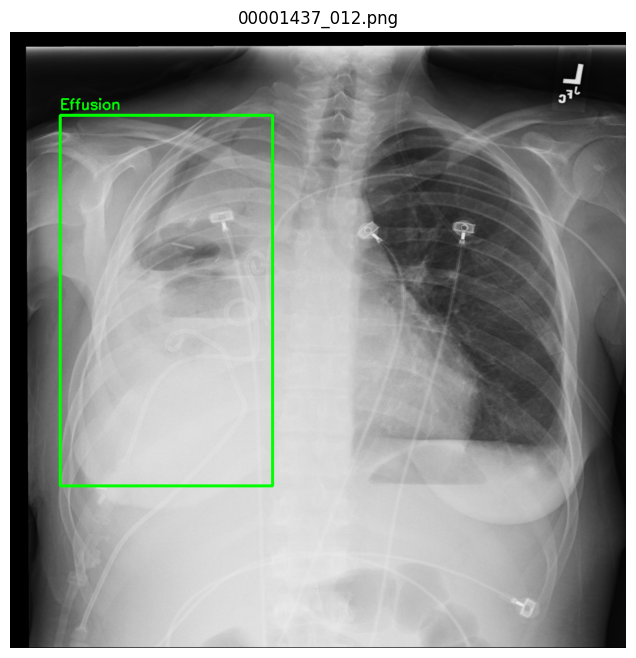

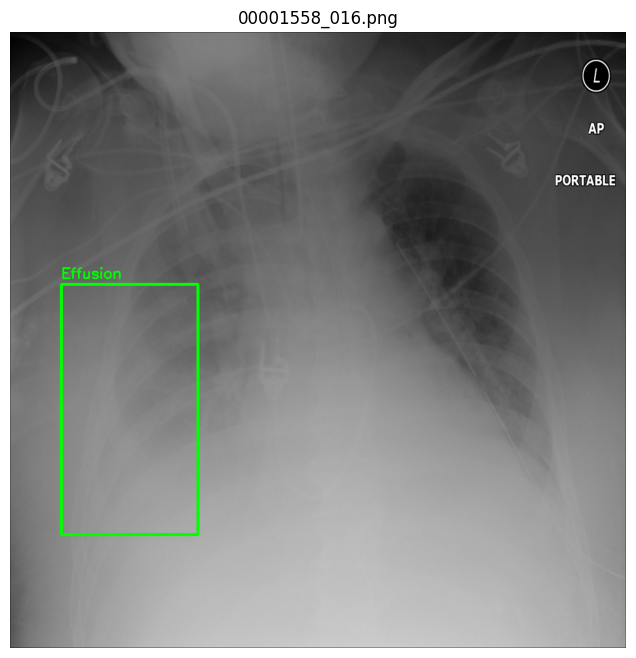

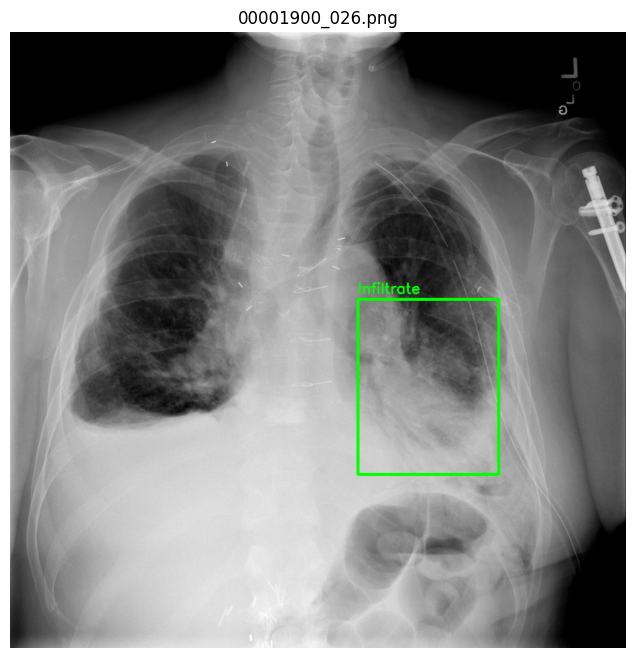

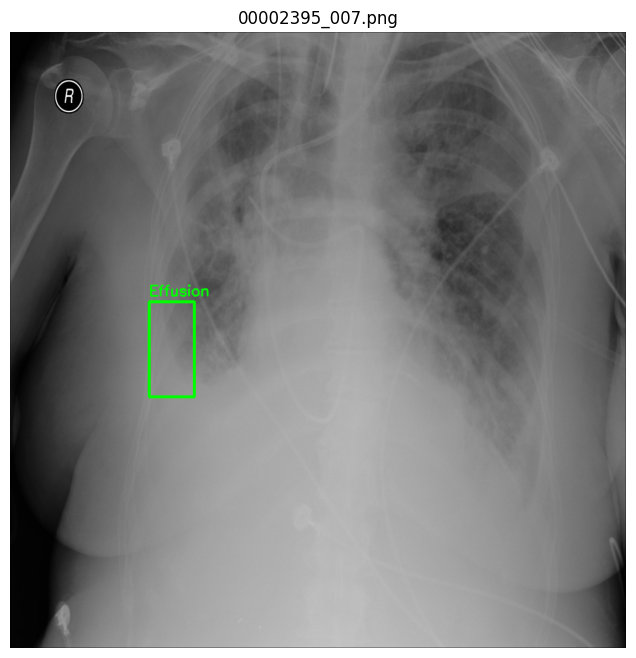

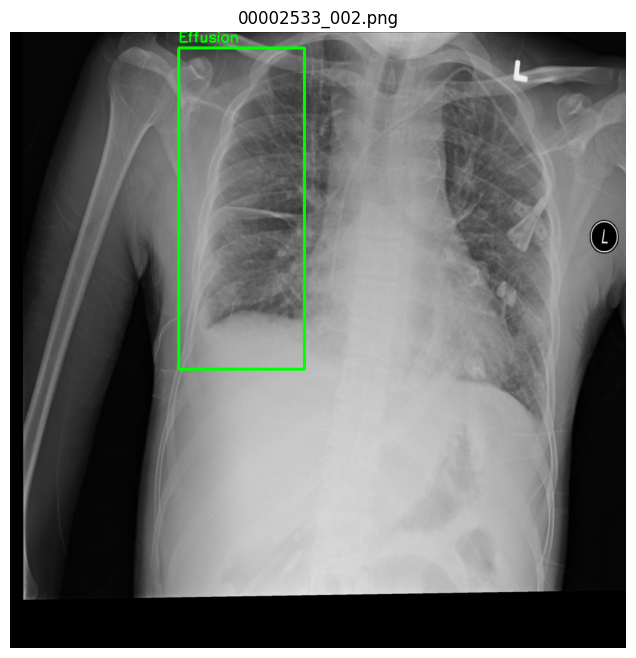

In [ ]:
# ============================================================
# SMART RAD XAI - BBOX MATCHING + LOCALIZATION VISUALIZATION
# ============================================================
# This code:
# 1. Reads your disease class folders
# 2. Fetches image details from Data_Entry_2017.csv
# 3. Matches images with BBox_List_2017.csv
# 4. Draws localization bounding boxes
# 5. Saves localized images
# 6. Creates matched image CSV
# ============================================================

# =========================
# IMPORT LIBRARIES
# =========================
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# FILE PATHS
# =========================

# Disease class folders path
dataset_path = "/content/drive/MyDrive/Disease classes"

# Main NIH CSV
data_entry_path = "/content/drive/MyDrive/Data_Entry_2017.csv"

# Bounding Box CSV
bbox_path = "/content/drive/MyDrive/BBox_List_2017.csv"

# Output folder
output_folder = "/content/drive/MyDrive/Localized_Output"

# Create output directory
os.makedirs(output_folder, exist_ok=True)

# =========================
# LOAD CSV FILES
# =========================
print("Loading CSV files...")

data_df = pd.read_csv(data_entry_path)
bbox_df = pd.read_csv(bbox_path)

print("CSV files loaded successfully.")

# =========================
# CLEAN COLUMN NAMES
# =========================
bbox_df.columns = bbox_df.columns.str.strip()
data_df.columns = data_df.columns.str.strip()

# =========================
# GET BBOX IMAGE NAMES
# =========================
bbox_images = set(bbox_df['Image Index'])

print(f"\nTotal BBox annotated images: {len(bbox_images)}")

# =========================
# MATCH IMAGES
# =========================
matched_records = []

print("\nScanning disease folders...\n")

for disease_class in os.listdir(dataset_path):

    class_path = os.path.join(dataset_path, disease_class)

    if os.path.isdir(class_path):

        print(f"Processing class: {disease_class}")

        # Create output class folder
        save_class_folder = os.path.join(output_folder, disease_class)
        os.makedirs(save_class_folder, exist_ok=True)

        for image_name in os.listdir(class_path):

            image_path = os.path.join(class_path, image_name)

            # =========================
            # CHECK IMAGE IN MAIN CSV
            # =========================
            main_match = data_df[
                data_df['Image Index'] == image_name
            ]

            if len(main_match) > 0:

                # =========================
                # CHECK IMAGE IN BBOX CSV
                # =========================
                if image_name in bbox_images:

                    bbox_rows = bbox_df[
                        bbox_df['Image Index'] == image_name
                    ]

                    # Read image
                    image = cv2.imread(image_path)

                    if image is None:
                        continue

                    # Draw all bounding boxes
                    for _, row in bbox_rows.iterrows():

                        x = int(row['Bbox [x'])
                        y = int(row['y'])
                        w = int(row['w'])
                        h = int(row['h]'])

                        disease_label = row['Finding Label']

                        # Draw rectangle
                        cv2.rectangle(
                            image,
                            (x, y),
                            (x + w, y + h),
                            (0, 255, 0),
                            3
                        )

                        # Add label text
                        cv2.putText(
                            image,
                            disease_label,
                            (x, y - 10),
                            cv2.FONT_HERSHEY_SIMPLEX,
                            0.8,
                            (0, 255, 0),
                            2
                        )

                    # Save localized image
                    save_path = os.path.join(
                        save_class_folder,
                        image_name
                    )

                    cv2.imwrite(save_path, image)

                    # Store matched record
                    matched_records.append({
                        "Class Folder": disease_class,
                        "Image Name": image_name,
                        "BBox Found": "YES",
                        "Saved Path": save_path
                    })

                else:

                    matched_records.append({
                        "Class Folder": disease_class,
                        "Image Name": image_name,
                        "BBox Found": "NO",
                        "Saved Path": "N/A"
                    })

# =========================
# SAVE MATCH RESULTS
# =========================
matched_df = pd.DataFrame(matched_records)

csv_save_path = "/content/drive/MyDrive/matched_bbox_results.csv"

matched_df.to_csv(csv_save_path, index=False)

# =========================
# FINAL OUTPUT
# =========================
print("\n===================================")
print("PROCESS COMPLETED SUCCESSFULLY")
print("===================================")

print(f"\nLocalized images saved at:")
print(output_folder)

print(f"\nMatched CSV saved at:")
print(csv_save_path)

print(f"\nTotal processed images: {len(matched_df)}")

print("\nBBox Match Summary:")
print(matched_df['BBox Found'].value_counts())

# =========================
# DISPLAY SAMPLE OUTPUTS
# =========================
print("\nShowing sample localized images...\n")

sample_images = matched_df[
    matched_df['BBox Found'] == 'YES'
].head(5)

for idx, row in sample_images.iterrows():

    img = cv2.imread(row['Saved Path'])

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8,8))
    plt.imshow(img_rgb)
    plt.title(row['Image Name'])
    plt.axis("off")
    plt.show()

In [ ]:
# ============================================================
# SMART RAD XAI - FINAL INFERENCE SYSTEM
# YOLO + NIH Bounding Box Explainability
# ============================================================

# =========================
# 1. INSTALL DEPENDENCIES
# =========================
!pip install ultralytics opencv-python pandas matplotlib

# =========================
# 2. IMPORT LIBRARIES
# =========================
from ultralytics import YOLO
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import files

# =========================
# 3. LOAD YOLO MODEL
# =========================
model_path = "/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/weights/best.pt"
model = YOLO(model_path)

print("✅ YOLO model loaded successfully!")

# =========================
# 4. LOAD NIH BBOX FILE
# =========================
bbox_path = "/content/drive/MyDrive/BBox_List_2017.csv"
bbox_df = pd.read_csv(bbox_path)

# Clean column names
bbox_df.columns = bbox_df.columns.str.strip()

# Set of images having bounding boxes
bbox_images = set(bbox_df["Image Index"])

print(f"✅ BBox file loaded: {len(bbox_images)} annotated images")

# =========================
# 5. UPLOAD IMAGE
# =========================
print("📤 Upload an X-ray image...")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
print("📷 Image selected:", image_path)

# =========================
# 6. RUN YOLO PREDICTION
# =========================
results = model.predict(source=image_path, conf=0.25)

# Read image
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("🧠 YOLO prediction completed!")

# =========================
# 7. DRAW YOLO PREDICTIONS
# =========================
for r in results:

    for box in r.boxes:

        x1, y1, x2, y2 = box.xyxy[0].int().tolist()
        conf = float(box.conf[0])
        cls = int(box.cls[0])

        label = model.names[cls]

        # YOLO BOX (BLUE)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

        cv2.putText(
            img,
            f"{label} {conf:.2f}",
            (x1, y1 - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2
        )

# =========================
# 8. ADD NIH BBOX (IF EXISTS)
# =========================
image_name = os.path.basename(image_path)

if image_name in bbox_images:

    gt_rows = bbox_df[bbox_df["Image Index"] == image_name]

    for _, row in gt_rows.iterrows():

        x = int(row["Bbox [x"])
        y = int(row["y"])
        w = int(row["w"])
        h = int(row["h]"])

        gt_label = row["Finding Label"]

        # NIH GROUND TRUTH BOX (GREEN)
        cv2.rectangle(
            img,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            img,
            f"GT: {gt_label}",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    print("📍 NIH bounding box found and drawn!")
else:
    print("⚠️ No NIH bounding box available for this image.")

# =========================
# 9. DISPLAY FINAL RESULT
# =========================
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.title("SmartRad XAI - Disease Detection + Localization")
plt.show()

# =========================
# 10. PRINT FINAL SUMMARY
# =========================
print("\n==============================")
print("SMART RAD XAI RESULT SUMMARY")
print("==============================")

if len(results[0].boxes) > 0:

    for box in results[0].boxes:

        cls = int(box.cls[0])
        conf = float(box.conf[0])

        print(f"🧠 Prediction: {model.names[cls]} ({conf:.2f})")

else:
    print("No disease detected with confidence threshold.")

print("\n✅ System executed successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 33.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
✅ YOLO model loaded successfully!
✅ BBox file loaded: 880 annotated images
📤 Upload an X-ray image...


Saving pnemonia image.png to pnemonia image.png
📷 Image selected: pnemonia image.png

image 1/1 /content/pnemonia image.png: 128x128 Pneumothorax 0.54, Pneumonia 0.30, Effusion 0.16, No Finding 0.00, Cardiomegaly 0.00, 3.6ms
Speed: 21.8ms preprocess, 3.6ms inference, 0.1ms postprocess per image at shape (1, 3, 128, 128)
🧠 YOLO prediction completed!


TypeError: 'NoneType' object is not iterable

✅ YOLO model loaded successfully
✅ NIH BBox loaded: 880 images
📤 Upload X-ray image


Saving 00001362_006.png to 00001362_006.png
📷 Input image: 00001362_006.png

image 1/1 /content/00001362_006.png: 128x128 Effusion 0.97, Cardiomegaly 0.01, No Finding 0.01, Pneumothorax 0.00, Pneumonia 0.00, 3.8ms
Speed: 13.9ms preprocess, 3.8ms inference, 0.0ms postprocess per image at shape (1, 3, 128, 128)
⚠️ No YOLO detections found (showing raw image + NIH if available)
⚠️ No NIH annotation available for this image


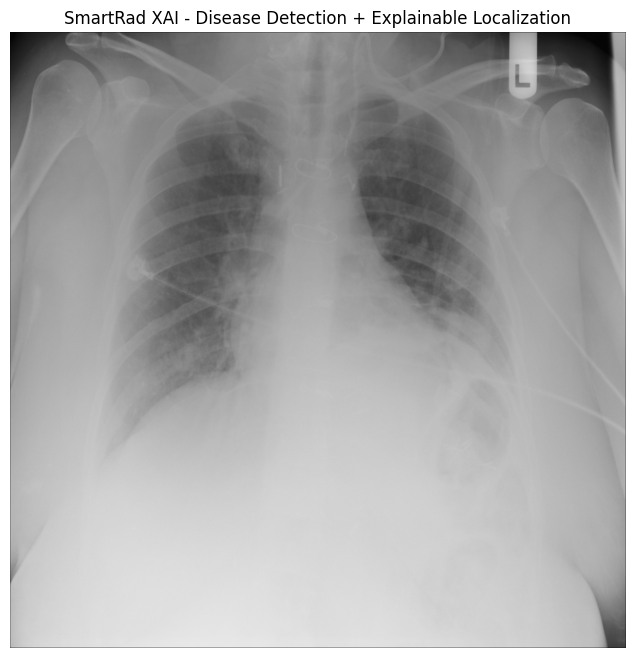


SMART RAD XAI FINAL REPORT
🧠 No disease detected by YOLO model
📍 Ground Truth: Not available

✅ Execution completed successfully!


In [ ]:
# ============================================================
# SMART RAD XAI - FINAL ROBUST INFERENCE PIPELINE
# YOLOv8 + NIH Bounding Boxes + Safe Error Handling
# ============================================================

# =========================
# 1. INSTALL LIBRARIES
# =========================
!pip install ultralytics opencv-python pandas matplotlib

# =========================
# 2. IMPORT LIBRARIES
# =========================
from ultralytics import YOLO
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import files

# =========================
# 3. LOAD YOLO MODEL
# =========================
model_path = "/content/drive/MyDrive/YOLO_Classification_Results/2026-02-16__disease_cls__1450/weights/best.pt"
model = YOLO(model_path)

print("✅ YOLO model loaded successfully")

# =========================
# 4. LOAD NIH BBOX DATA
# =========================
bbox_path = "/content/drive/MyDrive/BBox_List_2017.csv"
bbox_df = pd.read_csv(bbox_path)

bbox_df.columns = bbox_df.columns.str.strip()
bbox_images = set(bbox_df["Image Index"])

print(f"✅ NIH BBox loaded: {len(bbox_images)} images")

# =========================
# 5. UPLOAD IMAGE
# =========================
print("📤 Upload X-ray image")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]
print("📷 Input image:", image_path)

# =========================
# 6. RUN YOLO INFERENCE
# =========================
results = model.predict(source=image_path, conf=0.10)

# Read image
img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# =========================
# 7. HANDLE YOLO RESULTS SAFELY
# =========================
has_detection = False

for r in results:

    if r.boxes is not None and len(r.boxes) > 0:

        has_detection = True

        for box in r.boxes:

            x1, y1, x2, y2 = box.xyxy[0].int().tolist()
            conf = float(box.conf[0])
            cls = int(box.cls[0])

            label = model.names[cls]

            # YOLO BOX (BLUE)
            cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)

            cv2.putText(
                img,
                f"{label} {conf:.2f}",
                (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2
            )

if not has_detection:
    print("⚠️ No YOLO detections found (showing raw image + NIH if available)")

# =========================
# 8. NIH BOUNDING BOX OVERLAY
# =========================
image_name = os.path.basename(image_path)

if image_name in bbox_images:

    rows = bbox_df[bbox_df["Image Index"] == image_name]

    for _, row in rows.iterrows():

        x = int(row["Bbox [x"])
        y = int(row["y"])
        w = int(row["w"])
        h = int(row["h]"])
        label_gt = row["Finding Label"]

        # GREEN BOX (GROUND TRUTH)
        cv2.rectangle(
            img,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            img,
            f"GT: {label_gt}",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

    print("📍 NIH bounding box applied")

else:
    print("⚠️ No NIH annotation available for this image")

# =========================
# 9. DISPLAY FINAL RESULT
# =========================
plt.figure(figsize=(8, 8))
plt.imshow(img)
plt.axis("off")
plt.title("SmartRad XAI - Disease Detection + Explainable Localization")
plt.show()

# =========================
# 10. FINAL REPORT OUTPUT
# =========================
print("\n==============================")
print("SMART RAD XAI FINAL REPORT")
print("==============================")

if has_detection:
    for r in results:
        if r.boxes is not None:
            for box in r.boxes:
                cls = int(box.cls[0])
                conf = float(box.conf[0])
                print(f"🧠 Prediction: {model.names[cls]} ({conf:.2f})")
else:
    print("🧠 No disease detected by YOLO model")

if image_name in bbox_images:
    print("📍 Ground Truth: Available (NIH BBox matched)")
else:
    print("📍 Ground Truth: Not available")

print("\n✅ Execution completed successfully!")